# Ожидания к датасету

Записали пороги до того, как смотреть в данные, чтобы не подгонять их
под результат. Часть А это проверки и часть Б это гипотезы

## Часть А. Проверки

| что проверяем | порог | комментарий |
|---|---|---|
| колонки и типы | все на месте | |
| `rating` | только 1-5 | |
| `timestamp` vs партиция `year` | совпадает | |
| `helpful_vote` | >= 0 | |
| пропуски в `user_id`, `parent_asin`, `rating`, `timestamp` | 0% |  |
| полные дубли строк | 0 | |
| повторные отзывы юзера на один товар | < 1% |  |
| `parent_asin` в meta | уникален |  |
| отзывы, у которых товар есть в meta | >= 99% | |
| боты | нет | |
| пустые / короткие (< 3 слов) тексты | < 5% |  |

## Часть Б. Гипотезы

Считаем на данных после чистки по части А.

| что проверяем | ожидаем | что это даст |
|---|---|---|
| разреженность матрицы | > 99.9% | |
| юзеры с одним отзывом | > 50% |  |
| интеракции по времени | без провалов |  |
| `rating` >= 4 | >= 70% отзывов | |
| `title` у айтемов | >= 95% | |
| непустой `description` | >= 70% | |
| картинки | >= 90% | |
| контент у холодных vs тёплых | разница ≤ 10 п.п. |  |



## Подключение к S3

In [1]:
import os

import pandas as pd
import truststore

truststore.inject_into_ssl()

"AWS_ACCESS_KEY_ID" in os.environ, "AWS_SECRET_ACCESS_KEY" in os.environ

(True, True)

In [2]:
import s3fs

fs = s3fs.S3FileSystem(
    endpoint_url="https://s3.ru-7.storage.selcloud.ru",
    client_kwargs={"region_name": "ru-7"},
)
fs.ls("hse-recsys-project")

['hse-recsys-project/data']

In [3]:
fs.ls("hse-recsys-project/data/processed")

['hse-recsys-project/data/processed/meta',
 'hse-recsys-project/data/processed/reviews']

In [4]:
fs.ls("hse-recsys-project/data/processed/reviews")

['hse-recsys-project/data/processed/reviews/amazon_fashion',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food']

In [5]:
fs.ls("hse-recsys-project/data/processed/reviews/amazon_fashion")

['hse-recsys-project/data/processed/reviews/amazon_fashion/_SUCCESS',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2002',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2003',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2004',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2005',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2006',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2007',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2008',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2009',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2010',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2011',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2012',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2013',
 'hse-recsys-project/data/processed/reviews/amazon_fashion/year=2014',
 'hse-r

отзывы разложены по годам с 2002 по 2023

### Схема

In [6]:
import pyarrow.dataset as ds

base = "hse-recsys-project/data/processed"
for kind in ["reviews", "meta"]:
    d = ds.dataset(f"{base}/{kind}/amazon_fashion", filesystem=fs, partitioning="hive")
    print(kind)
    print(d.schema)
    print()

reviews
rating: int8
title: large_string
text: large_string
asin: large_string
parent_asin: large_string
user_id: large_string
timestamp: timestamp[ms]
helpful_vote: int32
verified_purchase: bool
n_images: int16
year: int32
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1337

meta
parent_asin: string
main_category: string
title: string
store: string
price: double
average_rating: double
rating_number: int64
features: list<element: string>
  child 0, element: string
description: list<element: string>
  child 0, element: string
categories: list<element: string>
  child 0, element: string
images: string
videos: string
details: string
bought_together: string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1759



In [7]:
meta_ds = ds.dataset(f"{base}/meta/amazon_fashion", filesystem=fs)
for field in meta_ds.schema:
    print(field.name, field.type)

parent_asin string
main_category string
title string
store string
price double
average_rating double
rating_number int64
features list<element: string>
description list<element: string>
categories list<element: string>
images string
videos string
details string
bought_together string


In [8]:
sample = meta_ds.head(3).to_pandas()
sample

,parent_asin,main_category,title,store,price,average_rating,rating_number,features,description,categories,images,videos,details,bought_together
0,B08BHN9PK5,AMAZON FASHION,YUEDGE 5 Pairs Men's Moisture Control Cushione...,GiveGift,NaN,4.6,16,[],[],[],"[{""thumb"": ""https://m.media-amazon.com/images/...",[],"{""Package Dimensions"": ""10.31 x 8.5 x 1.73 inc...",NaN
1,B08R39MRDW,AMAZON FASHION,DouBCQ Women's Palazzo Lounge Wide Leg Casual ...,DouBCQ,NaN,4.1,7,"[Drawstring closure, Machine Wash]",[],[],"[{""thumb"": ""https://m.media-amazon.com/images/...",[],"{""Package Dimensions"": ""15 x 10.2 x 0.4 inches...",NaN
2,B077KJHCJ4,AMAZON FASHION,Pastel by Vivienne Honey Vanilla Girls' Trapez...,Pastel by Vivienne,NaN,4.3,11,"[Zipper closure, Hand Wash Only]",[],[],"[{""thumb"": ""https://m.media-amazon.com/images/...",[],"{""Is Discontinued By Manufacturer"": ""No"", ""Pac...",NaN


In [9]:
print(sample.loc[0, "images"][:500])

[{"thumb": "https://m.media-amazon.com/images/I/41+cCfaVOFS._AC_SR38,50_.jpg", "large": "https://m.media-amazon.com/images/I/41+cCfaVOFS._AC_.jpg", "variant": "MAIN", "hi_res": "https://m.media-amazon.com/images/I/81XlFXImFrS._AC_UL1500_.jpg"}, {"thumb": "https://m.media-amazon.com/images/I/41jBdP7etRS._AC_SR38,50_.jpg", "large": "https://m.media-amazon.com/images/I/41jBdP7etRS._AC_.jpg", "variant": "PT01", "hi_res": "https://m.media-amazon.com/images/I/61+yVkHHQ3S._AC_UL1200_.jpg"}, {"thumb": "


images хранится как JSON-строка со списком фото. на первых товарах пустые description, categories, price, проверим долю на всех данных

### Загрузка отзывов

In [10]:
reviews_ds = ds.dataset(
    f"{base}/reviews/amazon_fashion", filesystem=fs, partitioning="hive"
)

cols = [
    "user_id",
    "parent_asin",
    "asin",
    "rating",
    "timestamp",
    "helpful_vote",
    "verified_purchase",
    "n_images",
    "year",
]

reviews = reviews_ds.to_table(columns=cols).to_pandas()
reviews.shape

(2500939, 9)

In [11]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500939 entries, 0 to 2500938
Data columns (total 9 columns):
 #   Column             Dtype         
---  ------             -----         
 0   user_id            str           
 1   parent_asin        str           
 2   asin               str           
 3   rating             int8          
 4   timestamp          datetime64[ms]
 5   helpful_vote       int32         
 6   verified_purchase  bool          
 7   n_images           int16         
 8   year               int32         
dtypes: bool(1), datetime64[ms](1), int16(1), int32(2), int8(1), str(3)
memory usage: 219.4 MB


## Часть А. проверки 

### Пропуски

In [12]:
reviews.isna().sum()

user_id              0
parent_asin          0
asin                 0
rating               0
timestamp            0
helpful_vote         0
verified_purchase    0
n_images             0
year                 0
dtype: int64

пропусков нет ни в одной колонке

### Значения

In [13]:
results = []


def expect(name, fact, ok, comment=""):
    results.append({"проверка": name, "факт": fact, "ok": ok, "комментарий": comment})

In [14]:
key_cols = ["user_id", "parent_asin", "rating", "timestamp"]
n_missing = int(reviews[key_cols].isna().sum().sum())
n_empty_ids = int(
    (reviews["user_id"] == "").sum() + (reviews["parent_asin"] == "").sum()
)
expect(
    "пропуски в ключевых колонках",
    n_missing + n_empty_ids,
    n_missing + n_empty_ids == 0,
)

bad_rating = int((~reviews["rating"].between(1, 5)).sum())
expect("rating только 1-5", bad_rating, bad_rating == 0)

year_mismatch = int((reviews["timestamp"].dt.year != reviews["year"]).sum())
expect("timestamp совпадает с year", year_mismatch, year_mismatch == 0)

neg_votes = int((reviews["helpful_vote"] < 0).sum())
expect("helpful_vote >= 0", neg_votes, neg_votes == 0)

pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,


схема и значения корректны: оценки 1-5, даты совпадают с партициями, отрицательных helpful_vote нет 

### Дубликаты 

In [15]:
n_full_dup = int(reviews.duplicated().sum())
expect("полные дубли строк", n_full_dup, n_full_dup == 0, "сравнивали без title и text")

repeat_share = reviews.duplicated(["user_id", "parent_asin"]).mean()
expect("повторные отзывы юзера на товар", f"{repeat_share:.2%}", repeat_share < 0.01)

pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,
4,полные дубли строк,25244,False,сравнивали без title и text
5,повторные отзывы юзера на товар,1.06%,False,


In [16]:
dedup = reviews.drop_duplicates()
real_repeat_share = dedup.duplicated(["user_id", "parent_asin"]).mean()
print(len(dedup), f"{real_repeat_share:.2%}")

2475695 0.05%


In [17]:
expect(
    "повторы после удаления дублей",
    f"{real_repeat_share:.2%}",
    real_repeat_share < 0.01,
    "оставляем, могут быть разные размеры/цвета",
)
reviews_clean = dedup
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,
4,полные дубли строк,25244,False,сравнивали без title и text
5,повторные отзывы юзера на товар,1.06%,False,
6,повторы после удаления дублей,0.05%,True,"оставляем, могут быть разные размеры/цвета"


дубликаты: нашли 25 244 полных дубля: совпадают юзер,
товар, оценка и время до миллисекунды. это артефакт данных, в ETL удаляем.

повторные отзывы юзера на один товар 1.06%, но почти все они
и есть эти дубли. после удаления дублей остаётся 0.05% честных повторов,
порог < 1% выполняется. они могут быть покупками разных размеров или
цветов одного товара (`parent_asin` их объединяет), оставляем

### Связь с каталогом 

In [18]:
meta_ids = meta_ds.to_table(columns=["parent_asin"]).to_pandas()

n_meta_dup = int(meta_ids["parent_asin"].duplicated().sum())
expect(
    "parent_asin в meta уникален",
    n_meta_dup,
    n_meta_dup == 0,
    "каждый товар один раз в каталоге",
)

in_meta_share = reviews_clean["parent_asin"].isin(meta_ids["parent_asin"]).mean()
expect("товар отзыва есть в meta", f"{in_meta_share:.2%}", in_meta_share >= 0.99)

pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,
4,полные дубли строк,25244,False,сравнивали без title и text
5,повторные отзывы юзера на товар,1.06%,False,
6,повторы после удаления дублей,0.05%,True,"оставляем, могут быть разные размеры/цвета"
7,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
8,товар отзыва есть в meta,100.00%,True,


каждый товар встречается в каталоге один раз. карточка товара есть практически у всех отзывов. склеивать отзывы с каталогом безопасно

### Боты 

In [19]:
per_user = reviews_clean.groupby("user_id").size()
per_user.describe(percentiles=[0.5, 0.9, 0.99, 0.999])

count    2.035490e+06
mean     1.216265e+00
std      9.113782e-01
min      1.000000e+00
50%      1.000000e+00
90%      2.000000e+00
99%      4.000000e+00
99.9%    9.000000e+00
max      3.110000e+02
dtype: float64

In [20]:
same_moment = reviews_clean.groupby(["user_id", "timestamp"]).size()
same_moment.value_counts().sort_index()

1    2475683
2          6
Name: count, dtype: int64

In [21]:
top_users = per_user.nlargest(10).index

(
    reviews_clean[reviews_clean["user_id"].isin(top_users)]
    .groupby("user_id")["timestamp"]
    .agg(["count", "min", "max"])
    .sort_values("count", ascending=False)
)

,count,min,max
user_id,,,
AGZZXSMMS4WRHHJRBUJZI4FZDHKQ,311,2018-10-05 20:32:08.369,2023-02-27 22:43:29.344
AG73BVBKUOH22USSFJA5ZWL7AKXA,210,2015-03-08 00:17:09.000,2021-11-28 22:11:33.465
AEYVPPWR4CIKWX4BGYKCBCDL2CZQ,176,2016-11-02 13:54:46.000,2022-08-15 17:20:49.519
AFQQQ5LGNSQUEBGDCYBAZZE5T3DA,145,2019-07-21 18:01:01.189,2021-04-02 23:03:56.784
AG3HKK7MIKRQ7DOTNDOE63X2WJGQ,145,2019-08-13 16:50:48.242,2023-01-21 17:23:46.870
AH5HSMUMRJRDWBPFDQ6G3EAAOSFQ,116,2018-08-16 18:20:30.957,2023-03-15 17:17:33.490
AH665SQ6SQF6DXAGYIQFCX76LALA,112,2015-11-17 20:43:11.000,2023-03-14 07:48:02.300
AEGYU6OM2X66SMZN6AF3TSQ3N5PQ,110,2017-06-28 02:04:33.998,2023-02-08 03:42:10.424
AEULD6UDDD7XSH2HXR2L6TNRHSNQ,108,2017-12-09 00:50:35.345,2023-03-11 01:58:03.373


In [22]:
expect(
    "боты", "не найдены", True, "нет пачек в один момент; самые активные пишут годами"
)
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,
4,полные дубли строк,25244,False,сравнивали без title и text
5,повторные отзывы юзера на товар,1.06%,False,
6,повторы после удаления дублей,0.05%,True,"оставляем, могут быть разные размеры/цвета"
7,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
8,товар отзыва есть в meta,100.00%,True,
9,боты,не найдены,True,нет пачек в один момент; самые активные пишут ...


боты: у половины юзеров 1 отзыв, у 99.9% не больше 9. максимум 311, но у самых активных отзывы растянуты на несколько лет, это похоже на частых покупателей, а не на накрутку. отзывов, выпущенных пачкой в одну миллисекунду, почти нет (6 пар на 2.5 млн). ничего не удаляем

### Короткие тексты 

In [23]:
texts = reviews_ds.to_table(
    columns=["user_id", "parent_asin", "timestamp", "text"]
).to_pandas()
texts = texts.drop_duplicates(subset=["user_id", "parent_asin", "timestamp"])

n_words = texts["text"].str.split().str.len()
short_share = (n_words.fillna(0) < 3).mean()
expect("пустые / короткие (< 3 слов) тексты", f"{short_share:.2%}", short_share < 0.05)
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,
4,полные дубли строк,25244,False,сравнивали без title и text
5,повторные отзывы юзера на товар,1.06%,False,
6,повторы после удаления дублей,0.05%,True,"оставляем, могут быть разные размеры/цвета"
7,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
8,товар отзыва есть в meta,100.00%,True,
9,боты,не найдены,True,нет пачек в один момент; самые активные пишут ...


In [24]:
texts.loc[n_words < 3, "text"].sample(15, random_state=42)

1105625    great quality.
1546901         Awesome!!
1364718        Excellent!
618349          Beautiful
845040           loved it
1857786              Like
1076012          Perfect!
405433            love it
1840270     Winter jacket
40376          Super cute
1251431     Great quality
1461497        Fit great!
1750797        It’s cheap
2088973                  
401019           Good kit
Name: text, dtype: str

In [25]:
n_empty = int((n_words.fillna(0) == 0).sum())
print(n_empty, f"{n_empty / len(texts):.2%}")

2393 0.10%


In [26]:
expect(
    "решение по коротким текстам",
    "оставляем",
    True,
    "короткие отзывы осмысленные, взаимодействие настоящее",
)
del texts
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,
4,полные дубли строк,25244,False,сравнивали без title и text
5,повторные отзывы юзера на товар,1.06%,False,
6,повторы после удаления дублей,0.05%,True,"оставляем, могут быть разные размеры/цвета"
7,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
8,товар отзыва есть в meta,100.00%,True,
9,боты,не найдены,True,нет пачек в один момент; самые активные пишут ...


отзывов короче трёх слов 8.24%, порог < 5% не выполнен. но почти все они
осмысленные: про размер, посадку и качество ("Fit great!", "Ridiculously small"),
для одежды это нормально. совсем пустых текстов всего 0.10% (2 393 отзыва)

отзывы не удаляем: даже с коротким текстом это настоящий отзыв

## Итог части А

данные Fashion в хорошем состоянии: пропусков нет, значения корректны, ботов не нашли, у всех отзывов есть карточка товара в каталоге

что делаем в ETL: удаляем 25 244 полных дубля (~1%).
остальное оставляем как есть. после чистки 2 475 695 отзывов

## Часть Б. Гипотезы по fashion

In [27]:
print(reviews_clean.shape)
reviews_clean.head(3)

(2475695, 9)


,user_id,parent_asin,asin,rating,timestamp,helpful_vote,verified_purchase,n_images,year
0,AEKTFS4F5725ATMN236AVWCGVTCA,B00007CWBQ,B00007CWBQ,4,2002-12-11 20:54:14,0,False,0,2002
1,AFMMNPUBZIB6F2TVT7FNHE3GDAQQ,B00005RCSK,B00005RCSK,5,2002-10-05 07:53:31,0,False,0,2002
2,AGKEIHAHRXEOXCUVQVOWECIA4L6A,B00005RCSK,B00005RCSK,5,2002-07-23 20:54:50,5,False,0,2002


### Разреженность

In [28]:
n_users = reviews_clean["user_id"].nunique()
n_items = reviews_clean["parent_asin"].nunique()
print(f"юзеров: {n_users:,}, товаров: {n_items:,}")

юзеров: 2,035,490, товаров: 825,869


In [29]:
pairs = reviews_clean[["user_id", "parent_asin"]].drop_duplicates()
n_pairs = len(pairs)

density = n_pairs / (n_users * n_items)
sparsity = 1 - density

print(f"уникальных пар: {n_pairs:,}")
print(f"плотность: {density:.2e}, разреженность: {sparsity:.5%}")

уникальных пар: 2,474,375
плотность: 1.47e-06, разреженность: 99.99985%


In [30]:
expect(
    "разреженность матрицы > 99.9%",
    f"{sparsity:.5%}",
    sparsity > 0.999,
    "1.5 клетки на млн, пересечений между юзерами почти нет",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
10,пустые / короткие (< 3 слов) тексты,8.24%,False,
11,решение по коротким текстам,оставляем,True,"короткие отзывы осмысленные, взаимодействие на..."
12,разреженность матрицы > 99.9%,99.99985%,True,"1.5 клетки на млн, пересечений между юзерами п..."


разреженность 99.99985%, порог выполнен. 2.47 млн уникальных пар на 2.04 млн юзеров и 826 тыс. товаров: в среднем ~1.2 товара на юзера. пересечений между юзерами почти нет

### Юзеры с одним отзывом

In [31]:
user_cnt = pairs.groupby("user_id").size()
user_cnt.head()

user_id
AE22236AFRRSMQIKGG7TPTB75QEA    1
AE2224EKBYOTIAXL7PC7KRQIXHOA    1
AE222GY2VH7MEWI4N5AHPXB5CP5A    1
AE222H3FGXWLHRFUMGMS2RR57NDQ    2
AE222NQXWES2RIDV6R47JZFJAVEA    1
dtype: int64

In [32]:
share_users_1 = (user_cnt == 1).mean()
print(f"юзеров с одним товаром: {share_users_1:.1%}")

юзеров с одним товаром: 86.2%


In [33]:
user_cnt.value_counts().sort_index().head(10)

1     1754095
2      204640
3       46764
4       15260
5        6384
6        3024
7        1670
8         983
9         668
10        431
Name: count, dtype: int64

In [34]:
active = user_cnt >= 5
print(f"юзеров с 5+ товарами: {active.sum():,} ({active.mean():.2%})")
print(f"максимум у одного юзера: {user_cnt.max()}")

юзеров с 5+ товарами: 14,731 (0.72%)
максимум у одного юзера: 311


In [35]:
expect(
    "юзеры с одним отзывом > 50%",
    f"{share_users_1:.1%}",
    share_users_1 > 0.5,
    "5+ товаров только у 0.72% юзеров (14.7 тыс.), максимум 311",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
11,решение по коротким текстам,оставляем,True,"короткие отзывы осмысленные, взаимодействие на..."
12,разреженность матрицы > 99.9%,99.99985%,True,"1.5 клетки на млн, пересечений между юзерами п..."
13,юзеры с одним отзывом > 50%,86.2%,True,"5+ товаров только у 0.72% юзеров (14.7 тыс.), ..."


один товар у 86.2% юзеров (1.75 млн из 2.04 млн), порог > 50% выполнен. активных мало: 5 и больше товаров только у 14.7 тыс. юзеров
(0.72%), максимум 311. если оставить только активных, потеряем 99% людей. значит, для большинства юзеров истории нет, и рекомендовать им придётся по популярности или по похожести товаров (описания, картинки)

### Интеракции по времени

In [36]:
by_year = reviews_clean.groupby(reviews_clean["timestamp"].dt.year).size()
by_year

timestamp
2002         6
2003        10
2004        34
2005        69
2006       152
2007       855
2008      1162
2009      1400
2010      1852
2011      2965
2012      7326
2013     22703
2014     59001
2015    126743
2016    285667
2017    368056
2018    366004
2019    408044
2020    309192
2021    306600
2022    172299
2023     35555
dtype: int64

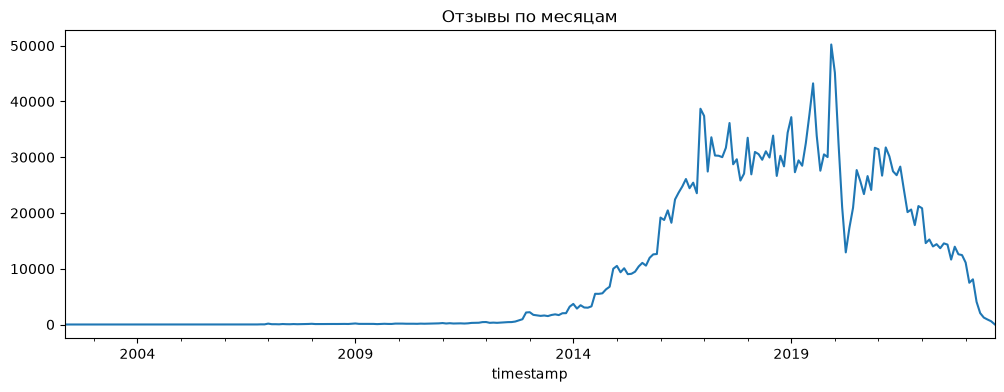

In [37]:
month = reviews_clean["timestamp"].dt.to_period("M")
by_month = reviews_clean.groupby(month).size()
by_month.plot(figsize=(12, 4), title="Отзывы по месяцам");

In [38]:
by_month["2019-01":"2021-06"]

timestamp
2019-01    37182
2019-02    27308
2019-03    29435
2019-04    28473
2019-05    32520
2019-06    37683
2019-07    43244
2019-08    33866
2019-09    27583
2019-10    30508
2019-11    30028
2019-12    50214
2020-01    45157
2020-02    32524
2020-03    21065
2020-04    12933
2020-05    17349
2020-06    20934
2020-07    27697
2020-08    25710
2020-09    23387
2020-10    26618
2020-11    24127
2020-12    31691
2021-01    31419
2021-02    26699
2021-03    31754
2021-04    30158
2021-05    27477
2021-06    26776
Freq: M, dtype: int64

In [39]:
main = by_month["2015-01":"2022-12"]
drops = main.pct_change()
drops.nsmallest(3)

timestamp
2020-04   -0.386043
2020-03   -0.352324
2022-02   -0.300082
Freq: M, dtype: float64

In [40]:
worst = drops.min()
no_gaps = len(main) == 8 * 12
print(f"месяцев в периоде: {len(main)}, самое сильное падение: {worst:.1%}")

expect(
    "интеракции по времени без провалов",
    f"{worst:.1%}",
    worst > -0.5 and no_gaps,
    "2015-2022 без пропущенных месяцев; яма весной 2020 (-39%), похоже на COVID",
)
pd.DataFrame(results).tail(3)

месяцев в периоде: 96, самое сильное падение: -38.6%


,проверка,факт,ok,комментарий
12,разреженность матрицы > 99.9%,99.99985%,True,"1.5 клетки на млн, пересечений между юзерами п..."
13,юзеры с одним отзывом > 50%,86.2%,True,"5+ товаров только у 0.72% юзеров (14.7 тыс.), ..."
14,интеракции по времени без провалов,-38.6%,True,2015-2022 без пропущенных месяцев; яма весной ...


отзывы распределены по времени неравномерно: до 2012 их почти нет, с 2013 по 2016 резкий рост, с 2016 по 2021 плато примерно 300-400 тыс. в год, с 2022 спад. 2023 неполный, датасет собран до осени 2023.

в основном периоде 2015-2022 все 96 месяцев на месте, самое сильное падение месяц к месяцу -38.6% (апрель 2020), порог -50% не нарушен, провалов нет. весной 2020 есть яма: с 50 тыс. в декабре 2019 до 12.9 тыс. в апреле, потом плавный подъём. похоже на влияние COVID, а не на потерю данных. ещё видна сезонность: в декабре всегда пик.

годы до 2015 почти пустые, а 2023 неполный

### rating >= 4

In [41]:
rating_share = reviews_clean["rating"].value_counts(normalize=True).sort_index()
rating_share

rating
1    0.121194
2    0.069347
3    0.098215
4    0.140945
5    0.570299
Name: proportion, dtype: float64

In [42]:
share_pos = (reviews_clean["rating"] >= 4).mean()
print(f"rating >= 4: {share_pos:.1%}")

rating >= 4: 71.1%


In [43]:
expect(
    "rating >= 4 у >= 70% отзывов",
    f"{share_pos:.1%}",
    share_pos >= 0.7,
    "впритык; пятерок 57%, единиц 12%, больше чем двоек и троек",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
13,юзеры с одним отзывом > 50%,86.2%,True,"5+ товаров только у 0.72% юзеров (14.7 тыс.), ..."
14,интеракции по времени без провалов,-38.6%,True,2015-2022 без пропущенных месяцев; яма весной ...
15,rating >= 4 у >= 70% отзывов,71.1%,True,"впритык; пятерок 57%, единиц 12%, больше чем д..."


rating >= 4 у 71.1% отзывов, порог >= 70% выполнен, но впритык. больше половины отзывов пятёрки (57%). единиц 12.1%, это больше, чем двоек (6.9%) и троек (9.8%): люди чаще пишут отзыв, когда вещь очень понравилась
или очень не понравилась. для Fashion это логично: не подошёл размер, цвет не как на фото. если считать позитивом 4-5, модель будет учиться на ~71% отзывов, а остальные 29% это негатив и нейтрал

### Контент товаров

In [44]:
meta = (
    ds.dataset("hse-recsys-project/data/processed/meta/amazon_fashion", filesystem=fs)
    .to_table(columns=["parent_asin", "title", "description", "features", "images"])
    .to_pandas()
)
meta.shape

(826108, 5)

In [45]:
meta.head(3)

,parent_asin,title,description,features,images
0,B08BHN9PK5,YUEDGE 5 Pairs Men's Moisture Control Cushione...,[],[],"[{""thumb"": ""https://m.media-amazon.com/images/..."
1,B08R39MRDW,DouBCQ Women's Palazzo Lounge Wide Leg Casual ...,[],"[Drawstring closure, Machine Wash]","[{""thumb"": ""https://m.media-amazon.com/images/..."
2,B077KJHCJ4,Pastel by Vivienne Honey Vanilla Girls' Trapez...,[],"[Zipper closure, Hand Wash Only]","[{""thumb"": ""https://m.media-amazon.com/images/..."


In [46]:
has_title = meta["title"].notna() & (meta["title"].str.strip() != "")
print(f"title есть: {has_title.mean():.1%}")

title есть: 100.0%


In [47]:
(~has_title).sum()

58

In [48]:
expect(
    "title у айтемов >= 95%",
    f"{has_title.mean():.2%}",
    has_title.mean() >= 0.95,
    "без title всего 58 товаров",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
14,интеракции по времени без провалов,-38.6%,True,2015-2022 без пропущенных месяцев; яма весной ...
15,rating >= 4 у >= 70% отзывов,71.1%,True,"впритык; пятерок 57%, единиц 12%, больше чем д..."
16,title у айтемов >= 95%,99.99%,True,без title всего 58 товаров


In [49]:
desc_text = meta["description"].str.join(" ").fillna("").str.strip()
has_desc = desc_text != ""

n_no_desc = (~has_desc).sum()
print(f"description есть: {has_desc.mean():.1%}, без description: {n_no_desc:,}")

description есть: 7.2%, без description: 766,819


In [50]:
print((meta["description"].str.len() > 0).mean())
desc_text[has_desc].head(3)

0.07176906651430563


3    Slip on the Women's Mento and you're ready to ...
4    Ronnox Calf Sleeves - Allowing Your Body to Pe...
8    Tie dye shirts for Women long sleeve crewneck ...
Name: description, dtype: object

In [51]:
expect(
    "непустой description >= 70%",
    f"{has_desc.mean():.1%}",
    has_desc.mean() >= 0.7,
    "почти нет описаний, 766 тыс. товаров без description",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
15,rating >= 4 у >= 70% отзывов,71.1%,True,"впритык; пятерок 57%, единиц 12%, больше чем д..."
16,title у айтемов >= 95%,99.99%,True,без title всего 58 товаров
17,непустой description >= 70%,7.2%,False,"почти нет описаний, 766 тыс. товаров без descr..."


In [52]:
feat_text = meta["features"].str.join(" ").fillna("").str.strip()
has_feat = feat_text != ""
print(f"features есть: {has_feat.mean():.1%}")
print(f"есть description или features: {(has_desc | has_feat).mean():.1%}")

features есть: 56.1%
есть description или features: 56.8%


In [53]:
meta["images"].value_counts().head(3)

images
[{"thumb": "https://m.media-amazon.com/images/I/01RmK+J4pJL._AC_SR38,50_.gif", "large": "https://m.media-amazon.com/images/I/01RmK+J4pJL._AC_.gif", "variant": "MAIN", "hi_res": null}]                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [54]:
top = meta["images"].value_counts()
print(top.head(3).values)
print("пустых []:", (meta["images"] == "[]").sum())
print("null:", meta["images"].isna().sum())

[10943  1119    87]
пустых []: 1
null: 0


In [55]:
placeholder = meta["images"].str.contains("01RmK+J4pJL", regex=False)
has_img = (meta["images"] != "[]") & ~placeholder
print(f"с заглушкой: {placeholder.sum():,}")
print(f"картинки есть: {has_img.mean():.1%}")

с заглушкой: 12,062
картинки есть: 98.5%


In [56]:
expect(
    "картинки >= 90%",
    f"{has_img.mean():.1%}",
    has_img.mean() >= 0.9,
    "12 062 товара с картинкой-заглушкой, считаем их без фото",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
16,title у айтемов >= 95%,99.99%,True,без title всего 58 товаров
17,непустой description >= 70%,7.2%,False,"почти нет описаний, 766 тыс. товаров без descr..."
18,картинки >= 90%,98.5%,True,"12 062 товара с картинкой-заглушкой, считаем и..."


title есть почти у всех товаров (99.99%, без названия всего 58). description заполнен только у 7.2% товаров, порог >= 70% не выполнен: у 766 тыс. товаров описания нет. зато есть features (пункты из карточки товара) у 56.1%, и они почти полностью перекрывают description: description или features есть у 56.8%. у остальных ~43% товаров из текста только название.

картинки есть у 98.5%, порог >= 90% выполнен. пустых списков почти нет, но у 12 062 товаров вместо фото стоит одна и та же gif-заглушка (проверила по ссылке), их считаем товарами без картинки

### Холодные vs теплые товары 

In [57]:
item_cnt = pairs.groupby("parent_asin").size()
meta["n_users"] = meta["parent_asin"].map(item_cnt).fillna(0)
is_warm = meta["n_users"] >= 5
print(f"тёплых товаров: {is_warm.sum():,} ({is_warm.mean():.1%})")

тёплых товаров: 93,728 (11.3%)


In [58]:
content = pd.DataFrame(
    {
        "title": has_title,
        "description": has_desc,
        "features": has_feat,
        "картинки": has_img,
    }
)
cmp = content.groupby(is_warm).mean() * 100
cmp.index = ["холодные", "тёплые"]
cmp.round(1)

,title,description,features,картинки
холодные,100.0,6.8,55.1,98.4
тёплые,100.0,10.2,63.9,99.4


In [59]:
diff = cmp.loc["тёплые"] - cmp.loc["холодные"]
max_diff = diff.abs().max()
print(diff.round(1))

title          0.0
description    3.4
features       8.8
картинки       0.9
dtype: double[pyarrow]


In [60]:
expect(
    "контент у холодных vs тёплых: разница <= 10 п.п.",
    f"{max_diff:.1f} п.п.",
    max_diff <= 10,
    "больше всего отстают features (55% против 64%); тёплый = 5+ юзеров",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
17,непустой description >= 70%,7.2%,False,"почти нет описаний, 766 тыс. товаров без descr..."
18,картинки >= 90%,98.5%,True,"12 062 товара с картинкой-заглушкой, считаем и..."
19,контент у холодных vs тёплых: разница <= 10 п.п.,8.8 п.п.,True,больше всего отстают features (55% против 64%)...


тёплым считаем товар, у которого 5 и больше юзеров. таких 93.7 тыс. (11.3%), остальные 88.7% холодные. контент у холодных заполнен чуть хуже, чем у тёплых, но разница небольшая: title одинаково (100%), картинки 98.4% против 99.4%, description 6.8% против 10.2%, features 55.1% против 63.9%. самая большая разница у features, 8.8 п.п., порог <= 10 п.п. выполнен. значит, для холодных товаров можно опираться на тот же контент, что и для тёплых: title, features и картинки

In [61]:
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,пропуски в ключевых колонках,0,True,
1,rating только 1-5,0,True,
2,timestamp совпадает с year,0,True,
3,helpful_vote >= 0,0,True,
4,полные дубли строк,25244,False,сравнивали без title и text
5,повторные отзывы юзера на товар,1.06%,False,
6,повторы после удаления дублей,0.05%,True,"оставляем, могут быть разные размеры/цвета"
7,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
8,товар отзыва есть в meta,100.00%,True,
9,боты,не найдены,True,нет пачек в один момент; самые активные пишут ...


## Итог части Б



данные очень разреженные (99.99985%), у 86.2% юзеров один товар, а 5 и больше
только у 0.72%. фильтр 5-core выкинул бы почти всех, поэтому для большинства
юзеров рекомендовать придётся без истории: по популярности или по похожести
товаров. по времени данные ровные, без провалов (яма весной 2020, похоже
COVID), можно делить на train/test по времени, учитывая, что до 2015 данных
почти нет, а 2023 неполный. позитивных оценок (4-5) 71.1%, впритык к порогу

из контента у товаров почти всегда есть title (99.99%) и картинки (98.5%,
заглушки посчитали как отсутствие фото). description почти пустой (7.2%),
вместо него можно брать features (56.1%). у холодных товаров контент
заполнен почти так же, как у тёплых (разница максимум 8.8 п.п. у features)